<a href="https://colab.research.google.com/github/wwwww22345/Assignment1_deep_learning/blob/main/Copy_of_Assigment_1_DL.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [1]:
!pip install torch torchvision matplotlib

In [2]:
# Task 1: Install and load PyTorch
import torch
import torch.nn as nn
import torch.optim as optim
import torchvision
from torchvision import datasets, transforms
import matplotlib.pyplot as plt

print("PyTorch version:", torch.__version__)
print("Torchvision version:", torchvision.__version__)

device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print("Using device:", device)

PyTorch version: 2.11.0+cpu
Torchvision version: 0.26.0+cpu
Using device: cpu


In [3]:
# Task 2: Download and Load the MNIST Dataset
from torch.utils.data import DataLoader

# Convert images to tensors
transform = transforms.ToTensor()

# Download the training and test sets
train_data = datasets.MNIST(root='data', train=True, download=True, transform=transform)
test_data  = datasets.MNIST(root='data', train=False, download=True, transform=transform)

# Load the data in mini-batches of 32
batch_size = 32
train_loader = DataLoader(train_data, batch_size=batch_size, shuffle=True)
test_loader  = DataLoader(test_data, batch_size=batch_size, shuffle=False)

# Confirm the dataset loaded successfully
print("Dataset loaded successfully!")
print("Training images:", len(train_data))
print("Test images:", len(test_data))
print("Single image shape:", train_data[0][0].shape)
print("Label of first image:", train_data[0][1])
print("Training batches:", len(train_loader))
print("Test batches:", len(test_loader))

100%|██████████| 9.91M/9.91M [00:02<00:00, 3.96MB/s]
100%|██████████| 28.9k/28.9k [00:00<00:00, 127kB/s]
100%|██████████| 1.65M/1.65M [00:01<00:00, 1.20MB/s]
100%|██████████| 4.54k/4.54k [00:00<00:00, 5.73MB/s]

Dataset loaded successfully!
Training images: 60000
Test images: 10000
Single image shape: torch.Size([1, 28, 28])
Label of first image: 5
Training batches: 1875
Test batches: 313


Images tensor size: torch.Size([32, 1, 28, 28])
Labels tensor size: torch.Size([32])


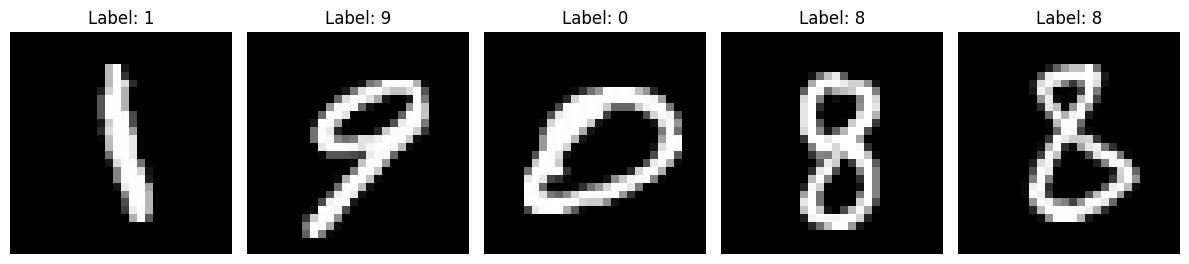

In [4]:
# Task 3: Inspect the Dataset

# Get one batch of images and labels
images, labels = next(iter(train_loader))

# 1. Print the tensor sizes
print("Images tensor size:", images.shape)
print("Labels tensor size:", labels.shape)

# 2. Visualize 5 images using Matplotlib
fig, axes = plt.subplots(1, 5, figsize=(12, 3))

for i in range(5):
    axes[i].imshow(images[i].squeeze(), cmap="gray")
    axes[i].set_title(f"Label: {labels[i].item()}")
    axes[i].axis("off")

plt.tight_layout()
plt.show()


**Task 3: Inspect the Dataset**

The image and label tensor sizes were examined using PyTorch. The images tensor has a shape of (32, 1, 28, 28), representing a batch of 32 grayscale images with dimensions of 28 × 28 pixels. Matplotlib was used to visualize five handwritten digits along with their corresponding labels.

In [5]:
#Task 4: Creating a Simple Network

import torch
import torch.nn as nn

#Neural Network Architecture
class SimpleNetwork(nn.Module):
    def __init__(self):
        super().__init__()

        self.fc1 = nn.Linear(784, 128) #Fully connected hidden layer with 128 neurons
        self.relu = nn.ReLU() #ReLU activation to introduce nonlinearity
        self.fc2 = nn.Linear(128, 10)  #Output layer with 10 neurons for digits 0-9

    def forward(self, x):

        # Flatten images from (32, 1, 28, 28) to (32, 784)
        x = torch.flatten(x, start_dim=1)

        x = self.fc1(x)
        x = self.relu(x)
        x = self.fc2(x)
        return x

model = SimpleNetwork()
print(model)
dummy_images = torch.randn(32, 1, 28, 28)
outputs = model(dummy_images)

print("\nInput shape:", dummy_images.shape)
print("Flattened shape:", torch.flatten(dummy_images, start_dim=1).shape)
print("Output shape:", outputs.shape)

assert outputs.shape == (32, 10)



SimpleNetwork(
  (fc1): Linear(in_features=784, out_features=128, bias=True)
  (relu): ReLU()
  (fc2): Linear(in_features=128, out_features=10, bias=True)
)

Input shape: torch.Size([32, 1, 28, 28])
Flattened shape: torch.Size([32, 784])
Output shape: torch.Size([32, 10])


In [ ]:
# Task 5: Training Function

import torch.optim as optim

# the train function takes the netowrk and the dataloader as inputs for training
def train_network(net, train_loader, epochs=5, learning_rate=0.01, momentum=0.9):

  # Loss Function apply a softmax to our network's output
    criterion = nn.CrossEntropyLoss()
  # Optimizer
    optimizer = optim.SGD(net.parameters(), lr=learning_rate, momentum=momentum)

    batch_losses = []

    for epoch in range(epochs):
        net.train()

        for batch_idx, (images, labels) in enumerate(train_loader):

            optimizer.zero_grad()

            # F
            outputs = net(images)
            loss = criterion(outputs, labels)

            loss.backward()
            optimizer.step()

            batch_losses.append(loss.item())

    return batch_losses
